**Universidade Federal da Bahia**, Escola Politécnica<br>
**Departamento de Engenharia Elétrica e de Computação**<br>
**Disciplina:** Introdução ao Aprendizado de Máquina (ENGG67)<br>
**Professor:** Antônio C. L. Fernandes Jr.<br>
**Aluno:** Eduardo Fontana<br>
**Semestre:** 2026.2

# Avaliação 01: análise exploratória do banco de dados Wine

Este notebook apresenta a análise exploratória do banco de dados Wine (UCI Machine Learning Repository, id 109), organizada conforme os itens da 1ª questão. Cada item reúne o código utilizado, os resultados obtidos e uma análise crítica que relaciona os resultados aos conceitos de análise e pré-processamento de dados apresentados nas notas de aula da disciplina.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.3f}".format)

## Carregamento dos dados

O arquivo `wine.data` não possui cabeçalho. Os nomes das colunas foram atribuídos com base no arquivo de documentação do banco (`wine.names`), que descreve os dados como resultado da análise química de vinhos produzidos em uma mesma região da Itália, provenientes de três cultivares diferentes, com a quantidade de 13 constituintes medida em cada vinho. A primeira coluna corresponde à classe (cultivar 1, 2 ou 3).

A documentação não informa as unidades de medida nem os métodos de análise de cada atributo. Por esse motivo, nenhuma unidade é atribuída aos atributos neste trabalho.

Caso o arquivo local não esteja disponível (por exemplo, no Google Colab), os dados são obtidos diretamente do repositório da UCI.

In [ ]:
COLUNAS = ["Alcohol", "Malic_acid", "Ash", "Alcalinity_of_ash", "Magnesium", "Total_phenols",
           "Flavanoids", "Nonflavanoid_phenols", "Proanthocyanins", "Color_intensity", "Hue",
           "OD280_OD315", "Proline"]

arquivo = Path("data/wine.data")
fonte = arquivo if arquivo.exists() else "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
df = pd.read_csv(fonte, header=None, names=["Class"] + COLUNAS)

X = df[COLUNAS]   # atributos preditivos
y = df["Class"]   # atributo alvo
df.head()

,Class,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline
0,1,14.230,1.710,2.430,15.600,127,2.800,3.060,0.280,2.290,5.640,1.040,3.920,1065
1,1,13.200,1.780,2.140,11.200,100,2.650,2.760,0.260,1.280,4.380,1.050,3.400,1050
2,1,13.160,2.360,2.670,18.600,101,2.800,3.240,0.300,2.810,5.680,1.030,3.170,1185
3,1,14.370,1.950,2.500,16.800,113,3.850,3.490,0.240,2.180,7.800,0.860,3.450,1480
4,1,13.240,2.590,2.870,21.000,118,2.800,2.690,0.390,1.820,4.320,1.040,2.930,735


## a) Univariado ou multivariado?

Um conjunto de dados é **univariado** quando cada objeto é descrito por um único atributo e **multivariado** quando é descrito por mais de um atributo. Os atributos dividem-se em **atributos preditivos**, que descrevem as características dos objetos, e **atributo alvo**, cujo valor rotula o objeto.

In [ ]:
n, d = X.shape
print(f"Número de objetos (n): {n}")
print(f"Número de atributos preditivos (d): {d}")
print(f"Atributo alvo: Class, com {y.nunique()} valores possíveis: {sorted(y.unique().tolist())}")

Número de objetos (n): 178
Número de atributos preditivos (d): 13
Atributo alvo: Class, com 3 valores possíveis: [1, 2, 3]


No banco Wine, cada um dos 178 objetos (vinhos) é descrito por **13 atributos preditivos**, correspondentes às quantidades dos constituintes químicos, e por **1 atributo alvo**, a cultivar de origem, com três valores possíveis (1, 2 e 3). Trata-se, portanto, de um conjunto **multivariado**, representado por uma matriz de objetos $X_{178 \times 13}$ acompanhada do vetor de rótulos.

Como o atributo alvo assume valores discretos que identificam categorias, a tarefa associada é de **classificação multiclasse**, no paradigma de aprendizado supervisionado. A dimensão do espaço de atributos ($d = 13$) impede a visualização direta dos objetos, o que motiva a redução de dimensionalidade realizada no item i. Observa-se ainda que a quantidade de objetos é pequena em relação ao número de atributos (cerca de 14 objetos por atributo), o que exige cautela com modelos de alta complexidade, mais sujeitos a superajuste (*overfitting*).

## b) Tipo e escala dos dados

O **tipo** de um atributo indica se ele representa quantidades (**quantitativo**) ou qualidades (**qualitativo**). A **escala** define as operações que podem ser aplicadas aos seus valores:

- **nominal**: os valores são apenas nomes diferentes, sem relação de ordem; admitem igualdade e desigualdade;
- **ordinal**: os valores refletem uma ordem; admitem também comparações (<, >);
- **intervalar**: a diferença entre valores tem significado, mas o zero é arbitrário;
- **racional**: existe um zero absoluto, de modo que a razão entre valores tem significado.

In [ ]:
descricao = ["Cultivar de origem", "Teor alcoólico", "Ácido málico", "Cinzas", "Alcalinidade das cinzas",
             "Magnésio", "Fenóis totais", "Flavonoides", "Fenóis não flavonoides", "Proantocianidinas",
             "Intensidade de cor", "Matiz", "OD280/OD315 de vinhos diluídos", "Prolina"]

tipo_escala = pd.DataFrame({
    "Descrição": descricao,
    "Tipo de dado no arquivo": df.dtypes.astype(str).values,
    "Tipo": ["Qualitativo"] + ["Quantitativo"] * 13,
    "Escala": ["Nominal"] + ["Racional"] * 13,
}, index=["Class"] + COLUNAS)
tipo_escala

,Descrição,Tipo de dado no arquivo,Tipo,Escala
Class,Cultivar de origem,int64,Qualitativo,Nominal
Alcohol,Teor alcoólico,float64,Quantitativo,Racional
Malic_acid,Ácido málico,float64,Quantitativo,Racional
Ash,Cinzas,float64,Quantitativo,Racional
Alcalinity_of_ash,Alcalinidade das cinzas,float64,Quantitativo,Racional
Magnesium,Magnésio,int64,Quantitativo,Racional
Total_phenols,Fenóis totais,float64,Quantitativo,Racional
Flavanoids,Flavonoides,float64,Quantitativo,Racional
Nonflavanoid_phenols,Fenóis não flavonoides,float64,Quantitativo,Racional
Proanthocyanins,Proantocianidinas,float64,Quantitativo,Racional


O atributo alvo `Class` é **qualitativo** e de escala **nominal**. Embora armazenado como número inteiro, os valores 1, 2 e 3 apenas identificam as cultivares, sem relação de ordem entre elas. Admitem, portanto, apenas operações de igualdade e desigualdade, e a medida de localidade adequada para esse atributo é a moda, e não a média.

Os 13 atributos preditivos são **quantitativos**, pois resultam de medições químicas e admitem operações aritméticas. Foram classificados na escala **racional** por representarem quantidades não negativas com zero absoluto: um valor nulo corresponderia à ausência da grandeza medida, e a razão entre dois valores tem significado. Os atributos `Magnesium` e `Proline` assumem apenas valores inteiros no arquivo; por representarem medidas de quantidade com grande número de valores distintos, receberam o mesmo tratamento dos demais atributos quantitativos.

Os atributos ocupam faixas de valores de ordens de grandeza muito diferentes: `Proline` varia de 278 a 1680, enquanto `Hue` varia de 0,48 a 1,71. Essa característica é determinante para as transformações dos itens h e i.

## c) Balanceamento e estatísticas univariadas

### c.1) Balanceamento das classes

,Frequência absoluta,Frequência relativa (%)
Class,,
1,59,33.100
2,71,39.900
3,48,27.000


Razão entre a maior e a menor classe: 1.48
Acurácia ao atribuir todos os objetos à classe majoritária (classe 2): 39.9%


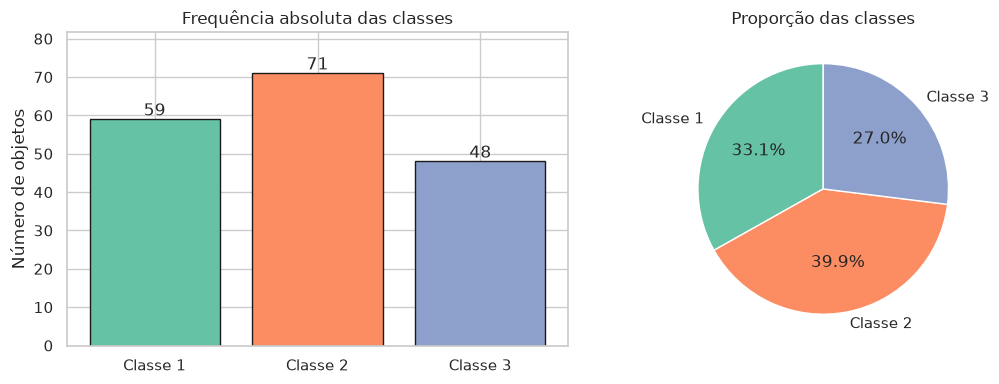

In [ ]:
freq = y.value_counts().sort_index()
tabela_classes = pd.DataFrame({"Frequência absoluta": freq,
                               "Frequência relativa (%)": 100 * freq / len(y)})
display(tabela_classes.round(1))
print(f"Razão entre a maior e a menor classe: {freq.max() / freq.min():.2f}")
print(f"Acurácia ao atribuir todos os objetos à classe majoritária (classe {freq.idxmax()}): "
      f"{100 * freq.max() / len(y):.1f}%")

cores_classes = sns.color_palette("Set2", 3)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar([f"Classe {k}" for k in freq.index], freq, color=cores_classes, edgecolor="k")
for i, v in enumerate(freq):
    ax[0].text(i, v + 1, str(v), ha="center")
ax[0].set(title="Frequência absoluta das classes", ylabel="Número de objetos", ylim=(0, freq.max() * 1.15))
ax[1].pie(freq, labels=[f"Classe {k}" for k in freq.index], autopct="%1.1f%%",
          colors=cores_classes, startangle=90, wedgeprops=dict(edgecolor="w"))
ax[1].set_title("Proporção das classes")
plt.tight_layout()
plt.show()

As três classes possuem 59, 71 e 48 objetos, correspondentes a 33,1%, 39,9% e 27,0% do total, e a razão entre a classe mais frequente e a menos frequente é de 1,48. Um conjunto é considerado desbalanceado quando algumas classes possuem quantidade significativamente maior de objetos que outras, situação que tende a induzir classificadores favoráveis às classes majoritárias. A diferença observada é pequena e todas as classes estão bem representadas, de modo que **o balanceamento foi considerado desnecessário**.

As técnicas de balanceamento estudadas também envolvem custos que não se justificam neste caso. A eliminação de objetos da classe majoritária pode descartar informação importante e levar a subajuste (*underfitting*). O acréscimo de objetos à classe minoritária pode introduzir exemplos que não representam situações reais e favorecer o superajuste. Com apenas 178 objetos, essas perdas seriam relevantes.

Dois cuidados decorrem dessa análise para uma etapa posterior de modelagem. O primeiro é que um classificador só é aceitável se sua acurácia superar 39,9%, valor obtido ao atribuir todos os objetos à classe majoritária (classe 2). O segundo é o uso de amostragem estratificada, como na validação cruzada estratificada, para preservar a proporção das classes em cada partição.

### c.2) Estatísticas univariadas dos atributos preditivos

Para cada atributo foram calculadas medidas de frequência, localidade, espalhamento e distribuição. A variância e o desvio padrão utilizam o denominador $n-1$. A obliquidade e a curtose foram implementadas com as fórmulas das notas de aula, baseadas nos momentos centrais de terceira e quarta ordem:

$$\text{obliquidade} = \frac{1}{(n-1)\,\sigma^3}\sum_{i=1}^{n}(x_i - \bar{x})^3
\qquad
\text{curtose} = \frac{1}{(n-1)\,\sigma^4}\sum_{i=1}^{n}(x_i - \bar{x})^4 - 3$$

Com o termo −3, uma distribuição normal tem curtose igual a zero.

In [ ]:
def obliquidade(D):
    n = len(D)
    return ((D - D.mean()) ** 3).sum() / ((n - 1) * D.std() ** 3)


def curtose(D):
    n = len(D)
    return ((D - D.mean()) ** 4).sum() / ((n - 1) * D.std() ** 4) - 3


moda = X.apply(lambda s: s.mode().iloc[0])
estatisticas = pd.DataFrame({
    "Valores distintos": X.nunique(),
    "Moda": moda,
    "Frequência da moda": [(X[c] == moda[c]).sum() for c in COLUNAS],
    "Média": X.mean(),
    "Mediana": X.median(),
    "Desvio padrão": X.std(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
    "Obliquidade": obliquidade(X),
    "Curtose": curtose(X),
})
estatisticas

,Valores distintos,Moda,Frequência da moda,Média,Mediana,Desvio padrão,Q1,Q3,Obliquidade,Curtose
Alcohol,126,12.370,6,13.001,13.050,0.812,12.362,13.678,-0.051,-0.874
Malic_acid,133,1.730,7,2.336,1.865,1.117,1.603,3.083,1.028,0.239
Ash,79,2.280,7,2.367,2.360,0.274,2.210,2.558,-0.175,1.056
Alcalinity_of_ash,63,20.000,15,19.495,19.500,3.340,17.200,21.500,0.211,0.421
Magnesium,53,88.000,13,99.742,98.000,14.282,88.000,107.000,1.086,1.985
Total_phenols,97,2.200,8,2.295,2.355,0.626,1.742,2.800,0.086,-0.858
Flavanoids,132,2.650,4,2.029,2.135,0.999,1.205,2.875,0.025,-0.901
Nonflavanoid_phenols,39,0.260,11,0.362,0.340,0.124,0.270,0.438,0.445,-0.666
Proanthocyanins,101,1.350,9,1.591,1.555,0.572,1.250,1.950,0.511,0.486
Color_intensity,132,2.600,4,5.058,4.690,2.318,3.220,6.200,0.859,0.319


In [ ]:
# Demais medidas de espalhamento: intervalo, variância, intervalo interquartil (IQR),
# desvio médio absoluto (AAD) e desvio mediano absoluto (MAD), conforme definidos em aula
espalhamento = pd.DataFrame({
    "Mínimo": X.min(),
    "Máximo": X.max(),
    "Intervalo": X.max() - X.min(),
    "Variância": X.var(),
    "IQR": X.quantile(0.75) - X.quantile(0.25),
    "AAD": (X - X.mean()).abs().mean(),
    "MAD": (X - X.mean()).abs().median(),
})
espalhamento

,Mínimo,Máximo,Intervalo,Variância,IQR,AAD,MAD
Alcohol,11.030,14.830,3.800,0.659,1.315,0.688,0.665
Malic_acid,0.740,5.800,5.060,1.248,1.480,0.920,0.741
Ash,1.360,3.230,1.870,0.075,0.348,0.209,0.167
Alcalinity_of_ash,10.600,30.000,19.400,11.153,4.300,2.595,2.050
Magnesium,70.000,162.000,92.000,203.989,19.000,10.999,10.500
Total_phenols,0.980,3.880,2.900,0.392,1.057,0.536,0.510
Flavanoids,0.340,5.080,4.740,0.998,1.670,0.859,0.841
Nonflavanoid_phenols,0.130,0.660,0.530,0.015,0.167,0.105,0.092
Proanthocyanins,0.410,3.580,3.170,0.328,0.700,0.446,0.359
Color_intensity,1.280,13.000,11.720,5.374,2.980,1.836,1.700


Como os atributos são contínuos, quase todos os valores são distintos (coluna *Valores distintos*), e a frequência de um valor isolado é pouco informativa. Por isso, reporta-se a frequência da moda, e a distribuição de frequências é analisada por meio dos histogramas do item g.

**Localidade.** Na maioria dos atributos, média e mediana são próximas (por exemplo, `Alcohol`, `Ash`, `Alcalinity_of_ash`, `Total_phenols` e `Hue`), o que indica distribuições aproximadamente simétricas. Em `Malic_acid`, `Magnesium`, `Color_intensity` e `Proline`, a média supera a mediana, comportamento típico de distribuições com cauda à direita, já que a média é mais sensível a valores extremos.

**Distribuição.** A obliquidade confirma essa leitura. É positiva e mais elevada em `Magnesium` (1,09), `Malic_acid` (1,03), `Color_intensity` (0,86) e `Proline` (0,76), o que indica concentração dos valores à esquerda e cauda à direita, e é próxima de zero nos atributos simétricos. Quanto à curtose, `Magnesium` (cerca de 2,0) e `Ash` (1,06) apresentam valores positivos, isto é, distribuições mais concentradas que a normal. `OD280_OD315` (−1,10), `Flavanoids` (−0,90), `Alcohol` (−0,87) e `Total_phenols` (−0,86) apresentam curtose negativa, ou seja, distribuições mais achatadas que a normal. O item g relaciona esse achatamento à presença das classes.

**Espalhamento.** Os desvios padrão variam de 0,12 (`Nonflavanoid_phenols`) a 314,91 (`Proline`). Essa diferença reflete sobretudo as escalas distintas dos atributos e não permite comparar diretamente a dispersão entre eles. O intervalo depende apenas dos valores mínimo e máximo e, por isso, é sensível a valores extremos: em `Proline`, o intervalo (1402) é cerca de três vezes o intervalo interquartil (484,5). O desvio mediano absoluto (MAD) é menor que o desvio médio absoluto (AAD) em todos os atributos, o que é coerente com a menor sensibilidade da mediana a valores extremos.

## d) Incompletude, inconsistências, redundâncias e ruído

Os principais problemas de qualidade de dados são:

- **dados incompletos**: ausência de valores para alguns atributos em parte dos objetos;
- **dados inconsistentes**: valores que não combinam ou contradizem valores de outros atributos;
- **dados redundantes**: objetos com os mesmos valores para todos os atributos, ou atributos cujo valor pode ser estimado a partir de outros;
- **dados ruidosos**: valores que aparentemente não pertencem à distribuição que gerou os dados.

### d.1) Dados incompletos e objetos redundantes

In [ ]:
print("Valores ausentes por atributo:")
print(df.isna().sum().to_string())
print(f"Total de valores ausentes: {df.isna().sum().sum()}")
print(f"Objetos duplicados (todas as colunas): {df.duplicated().sum()}")
print(f"Objetos duplicados (apenas atributos preditivos): {X.duplicated().sum()}")

Valores ausentes por atributo:
Class                   0
Alcohol                 0
Malic_acid              0
Ash                     0
Alcalinity_of_ash       0
Magnesium               0
Total_phenols           0
Flavanoids              0
Nonflavanoid_phenols    0
Proanthocyanins         0
Color_intensity         0
Hue                     0
OD280_OD315             0
Proline                 0
Total de valores ausentes: 0
Objetos duplicados (todas as colunas): 0
Objetos duplicados (apenas atributos preditivos): 0


### d.2) Dados inconsistentes

Verifica-se se os valores respeitam o domínio esperado: atributos não negativos, valores inteiros nos atributos armazenados como inteiros e rótulos de classe válidos.

In [ ]:
dominio = pd.DataFrame({"Mínimo": X.min(), "Máximo": X.max(), "Valores <= 0": (X <= 0).sum()})
display(dominio)
for c in ["Magnesium", "Proline"]:
    print(f"{c}: valores não inteiros = {int((X[c] % 1 != 0).sum())}")
print("Rótulos de classe encontrados:", sorted(y.unique().tolist()))

,Mínimo,Máximo,Valores <= 0
Alcohol,11.030,14.830,0
Malic_acid,0.740,5.800,0
Ash,1.360,3.230,0
Alcalinity_of_ash,10.600,30.000,0
Magnesium,70.000,162.000,0
Total_phenols,0.980,3.880,0
Flavanoids,0.340,5.080,0
Nonflavanoid_phenols,0.130,0.660,0
Proanthocyanins,0.410,3.580,0
Color_intensity,1.280,13.000,0


Magnesium: valores não inteiros = 0
Proline: valores não inteiros = 0
Rótulos de classe encontrados: [1, 2, 3]


### d.3) Dados ruidosos

O critério principal de identificação de outliers é o do **boxplot modificado**: são considerados outliers os valores abaixo de $Q1 - 1{,}5 \cdot IQR$ ou acima de $Q3 + 1{,}5 \cdot IQR$. Como critério complementar, utiliza-se o escore padronizado com limite $|z| > 3$: em uma distribuição normal, a probabilidade de um valor estar a mais de três desvios padrão da média é de apenas 0,0026.

Aplica-se também uma **técnica baseada em distância**: um objeto cujos vizinhos mais próximos pertencem, em sua maioria, a outra classe é candidato a ruído ou a objeto de fronteira (*borderline*). Foram considerados $k = 5$ vizinhos, com distância euclidiana calculada sobre os atributos padronizados (item h), para que nenhum atributo domine a distância por causa de sua escala.

In [ ]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
abaixo = X < q1 - 1.5 * iqr
acima = X > q3 + 1.5 * iqr
outlier = abaixo | acima
z = (X - X.mean()) / X.std()

tabela_outliers = pd.DataFrame({"Abaixo de Q1 - 1,5 IQR": abaixo.sum(),
                                "Acima de Q3 + 1,5 IQR": acima.sum(),
                                "Total (boxplot)": outlier.sum(),
                                "|z| > 3": (z.abs() > 3).sum()})
display(tabela_outliers[(tabela_outliers > 0).any(axis=1)])
print(f"Objetos com ao menos um outlier (boxplot): {outlier.any(axis=1).sum()} de {len(X)}")

,"Abaixo de Q1 - 1,5 IQR","Acima de Q3 + 1,5 IQR",Total (boxplot),|z| > 3
Malic_acid,0,3,3,1
Ash,1,2,3,3
Alcalinity_of_ash,1,3,4,1
Magnesium,0,4,4,2
Flavanoids,0,0,0,1
Proanthocyanins,0,2,2,1
Color_intensity,0,4,4,1
Hue,0,1,1,1


Objetos com ao menos um outlier (boxplot): 17 de 178


In [ ]:
# Técnica baseada em distância: fração dos k vizinhos mais próximos que pertencem a outra classe
Z = StandardScaler().fit_transform(X)
k = 5
vizinhos = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
rotulos = y.to_numpy()
fracao_outra_classe = (rotulos[vizinhos] != rotulos[:, None]).mean(axis=1)
candidatos = np.where(fracao_outra_classe > 0.5)[0]

print(f"Objetos com ao menos 1 dos {k} vizinhos em outra classe: {(fracao_outra_classe > 0).sum()}")
print(f"Objetos com a maioria dos vizinhos em outra classe: {len(candidatos)}")
print(f"Índices: {candidatos.tolist()} | classes: {rotulos[candidatos].tolist()}")
print(f"Desses, também são outliers pelo boxplot: {int(outlier.any(axis=1).to_numpy()[candidatos].sum())}")

Objetos com ao menos 1 dos 5 vizinhos em outra classe: 30
Objetos com a maioria dos vizinhos em outra classe: 5
Índices: [71, 73, 83, 95, 118] | classes: [2, 2, 2, 2, 2]
Desses, também são outliers pelo boxplot: 2


### d.4) Atributos redundantes

A redundância de um atributo está relacionada à sua correlação com os demais: quanto mais correlacionados os atributos, maior o grau de redundância. A tabela a seguir lista os pares com correlação de Pearson de módulo igual ou superior a 0,6, limiar adotado para destacar as relações mais fortes.

In [ ]:
corr = X.corr()
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("Correlação").reset_index()
         .rename(columns={"level_0": "Atributo A", "level_1": "Atributo B"}))
pares[pares["Correlação"].abs() >= 0.6].sort_values("Correlação", key=abs, ascending=False)

,Atributo A,Atributo B,Correlação
71,Total_phenols,Flavanoids,0.865
89,Flavanoids,OD280_OD315,0.787
76,Total_phenols,OD280_OD315,0.700
86,Flavanoids,Proanthocyanins,0.653
12,Alcohol,Proline,0.644
73,Total_phenols,Proanthocyanins,0.612


**Dados incompletos.** Não há valores ausentes em nenhum atributo. Nenhuma técnica de tratamento, como a eliminação de objetos ou o preenchimento de valores, é necessária.

**Dados inconsistentes.** Todos os valores são positivos, `Magnesium` e `Proline` contêm apenas valores inteiros e o atributo alvo contém apenas os rótulos 1, 2 e 3. Inconsistências também podem ser identificadas pela violação de relações conhecidas entre atributos. Contudo, a documentação do banco não descreve os métodos de medição nem as unidades, o que impede estabelecer com segurança relações desse tipo. Dentro do que pode ser verificado, não foram encontradas inconsistências.

**Dados redundantes.** Não há objetos duplicados. Entre os atributos, observa-se redundância parcial no grupo associado aos compostos fenólicos: `Total_phenols` e `Flavanoids` (0,86), `Flavanoids` e `OD280_OD315` (0,79) e `Total_phenols` e `OD280_OD315` (0,70). Nenhum par, porém, aproxima-se do caso extremo em que dois atributos compartilham praticamente os mesmos valores (correlação próxima de 1), de modo que cada atributo mantém uma parcela própria de informação. Optou-se por não eliminar atributos nesta etapa: como nenhum par é praticamente idêntico, a eliminação de um atributo implicaria perda de informação, e a análise de componentes principais (item i) trata a redundância por agregação, ao combinar atributos correlacionados.

**Dados ruidosos.** Há poucos outliers, entre 1 e 4 por atributo, em `Malic_acid`, `Ash`, `Alcalinity_of_ash`, `Magnesium`, `Proanthocyanins`, `Color_intensity` e `Hue`. No total, 17 dos 178 objetos (9,6%) possuem ao menos um valor fora dos limites do boxplot modificado, e o critério $|z| > 3$ aponta um conjunto semelhante. Pela técnica baseada em distância, apenas 5 objetos, todos da classe 2, têm a maioria dos vizinhos mais próximos em outra classe, e somente 2 deles coincidem com outliers do boxplot.

Não é possível ter certeza de que um valor é resultado de ruído: a presença de outliers é apenas um indício. Além disso, a eliminação de dados ruidosos pode levar à perda de informação importante e deixar regiões do espaço de atributos sem representação. Como os valores extremos são plausíveis para medidas de quantidade, correspondem a quase 10% dos objetos de um conjunto pequeno e não há evidência de erro de medição, optou-se por **manter todos os objetos**.

## e) Covariância e correlação

A **covariância** entre dois atributos mede o grau em que variam conjuntamente:

$$\text{cov}(x^i, x^j) = \frac{1}{n-1}\sum_{k=1}^{n}(x_k^i - \bar{x}^i)(x_k^j - \bar{x}^j)$$

A **correlação** divide a covariância pelo produto dos desvios padrão, $r = \text{cov}(x^i, x^j) / (s_i\, s_j)$, e assume valores entre −1 e +1.

,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline
Alcohol,0.660,0.090,0.050,-0.840,3.140,0.150,0.190,-0.020,0.060,1.030,-0.010,0.040,164.570
Malic_acid,0.090,1.250,0.050,1.080,-0.870,-0.230,-0.460,0.040,-0.140,0.640,-0.140,-0.290,-67.550
Ash,0.050,0.050,0.080,0.410,1.120,0.020,0.030,0.010,0.000,0.160,-0.000,0.000,19.320
Alcalinity_of_ash,-0.840,1.080,0.410,11.150,-3.970,-0.670,-1.170,0.150,-0.380,0.150,-0.210,-0.660,-463.360
Magnesium,3.140,-0.870,1.120,-3.970,203.990,1.920,2.790,-0.460,1.930,6.620,0.180,0.670,1769.160
Total_phenols,0.150,-0.230,0.020,-0.670,1.920,0.390,0.540,-0.040,0.220,-0.080,0.060,0.310,98.170
Flavanoids,0.190,-0.460,0.030,-1.170,2.790,0.540,1.000,-0.070,0.370,-0.400,0.120,0.560,155.450
Nonflavanoid_phenols,-0.020,0.040,0.010,0.150,-0.460,-0.040,-0.070,0.020,-0.030,0.040,-0.010,-0.040,-12.200
Proanthocyanins,0.060,-0.140,0.000,-0.380,1.930,0.220,0.370,-0.030,0.330,-0.030,0.040,0.210,59.550
Color_intensity,1.030,0.640,0.160,0.150,6.620,-0.080,-0.400,0.040,-0.030,5.370,-0.280,-0.710,230.770


Covariância dos atributos padronizados é igual à matriz de correlação: True


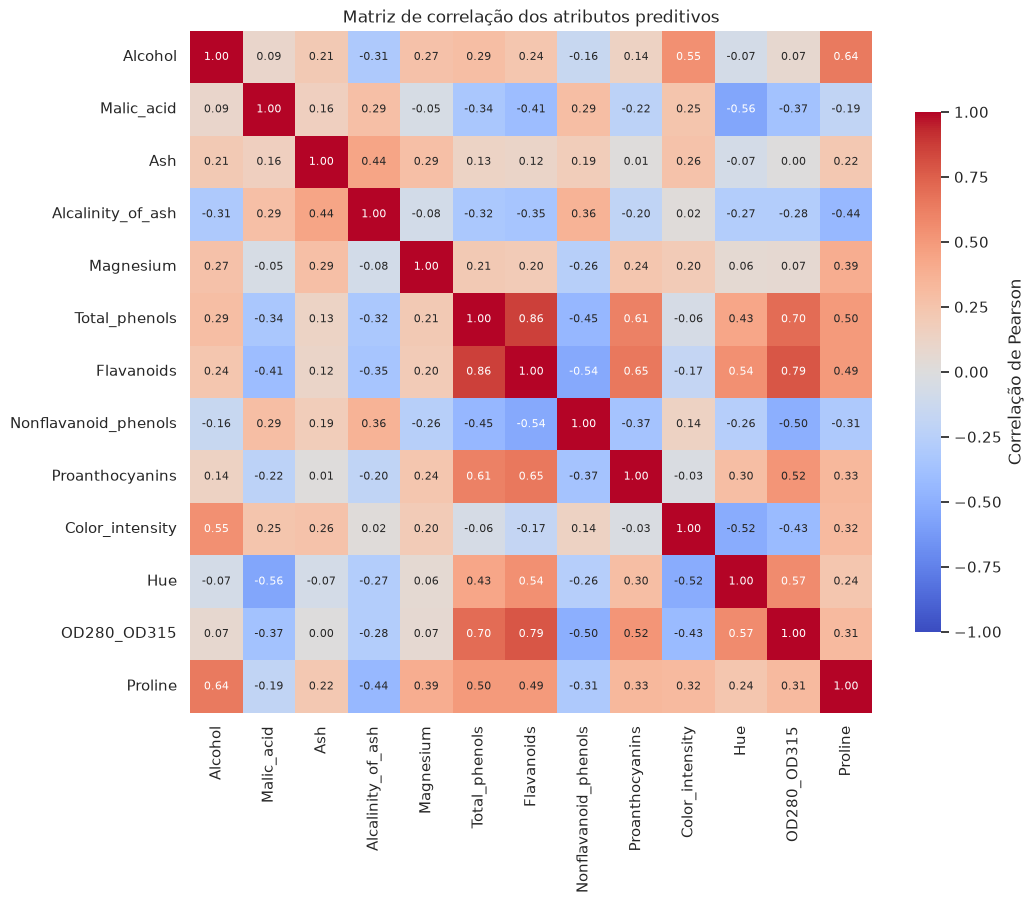

In [ ]:
cov = X.cov()
display(cov.round(2))

print("Covariância dos atributos padronizados é igual à matriz de correlação:",
      np.allclose(np.cov(Z, rowvar=False, ddof=0), corr))

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.75, "label": "Correlação de Pearson"})
plt.title("Matriz de correlação dos atributos preditivos")
plt.show()

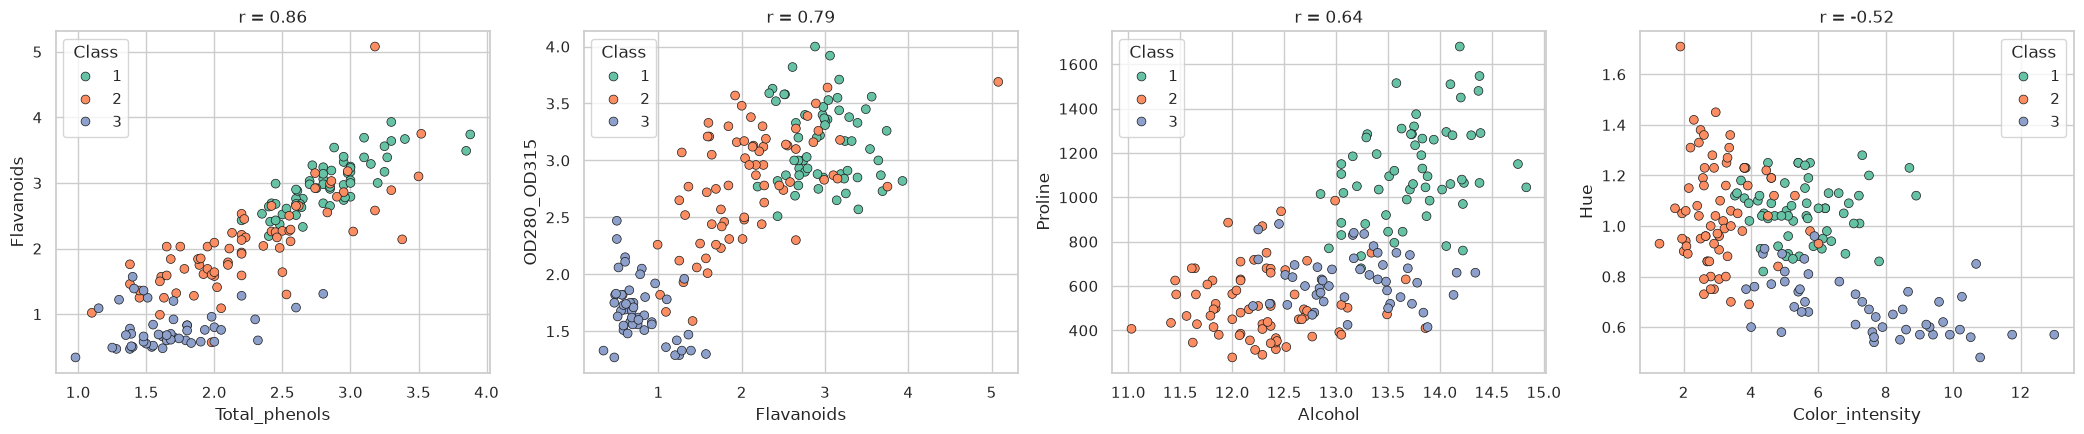

In [ ]:
# Diagramas de dispersão dos pares mais correlacionados, com as classes identificadas
pares_destaque = [("Total_phenols", "Flavanoids"), ("Flavanoids", "OD280_OD315"),
                  ("Alcohol", "Proline"), ("Color_intensity", "Hue")]
fig, axs = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, (a, b) in zip(axs, pares_destaque):
    sns.scatterplot(data=df, x=a, y=b, hue="Class", palette="Set2", s=40, edgecolor="k", ax=ax)
    ax.set_title(f"r = {corr.loc[a, b]:.2f}")
plt.tight_layout()
plt.show()

**Covariância.** Valores positivos indicam que os atributos variam no mesmo sentido, valores negativos indicam variação em sentidos opostos e valores próximos de zero indicam ausência de relação linear. O valor da covariância, porém, depende da magnitude dos atributos. Na matriz obtida, os maiores valores envolvem `Proline` (variância de aproximadamente 99.167) e `Magnesium` (aproximadamente 204), o que reflete as escalas desses atributos e não necessariamente relações mais fortes. Por esse motivo, a covariância não permite comparar a intensidade das relações entre diferentes pares de atributos.

**Correlação.** A correlação elimina a influência da escala e, por isso, é a medida mais adequada para explorar dados multivariados. O código confirma que a covariância dos atributos padronizados coincide com a matriz de correlação. As correlações positivas mais fortes ocorrem entre `Total_phenols` e `Flavanoids` (0,86), `Flavanoids` e `OD280_OD315` (0,79) e `Total_phenols` e `OD280_OD315` (0,70), atributos associados ao conteúdo fenólico. Destacam-se também `Flavanoids` e `Proanthocyanins` (0,65) e `Alcohol` e `Proline` (0,64). Entre as correlações negativas, as mais intensas são `Malic_acid` e `Hue` (−0,56), `Flavanoids` e `Nonflavanoid_phenols` (−0,54) e `Color_intensity` e `Hue` (−0,52). `Ash` e `Magnesium` apresentam correlações fracas com a maioria dos demais atributos.

**Influência das classes.** Os diagramas de dispersão mostram que parte dessas correlações acompanha a diferença entre as cultivares. Em `Total_phenols` × `Flavanoids`, por exemplo, as três classes ocupam regiões distintas ao longo da mesma tendência crescente. A correlação calculada sobre o conjunto completo combina, portanto, a relação entre os atributos e a separação entre as classes. Ressalta-se ainda que a correlação indica associação linear entre atributos, e não relação de causa e efeito.

## f) Boxplots e outliers

No boxplot, a caixa vai do primeiro (Q1) ao terceiro quartil (Q3) e a linha interna indica a mediana. No boxplot modificado, os bigodes estendem-se até o valor mais extremo situado a no máximo 1,5 IQR dos quartis, e os pontos além desses limites são exibidos como outliers.

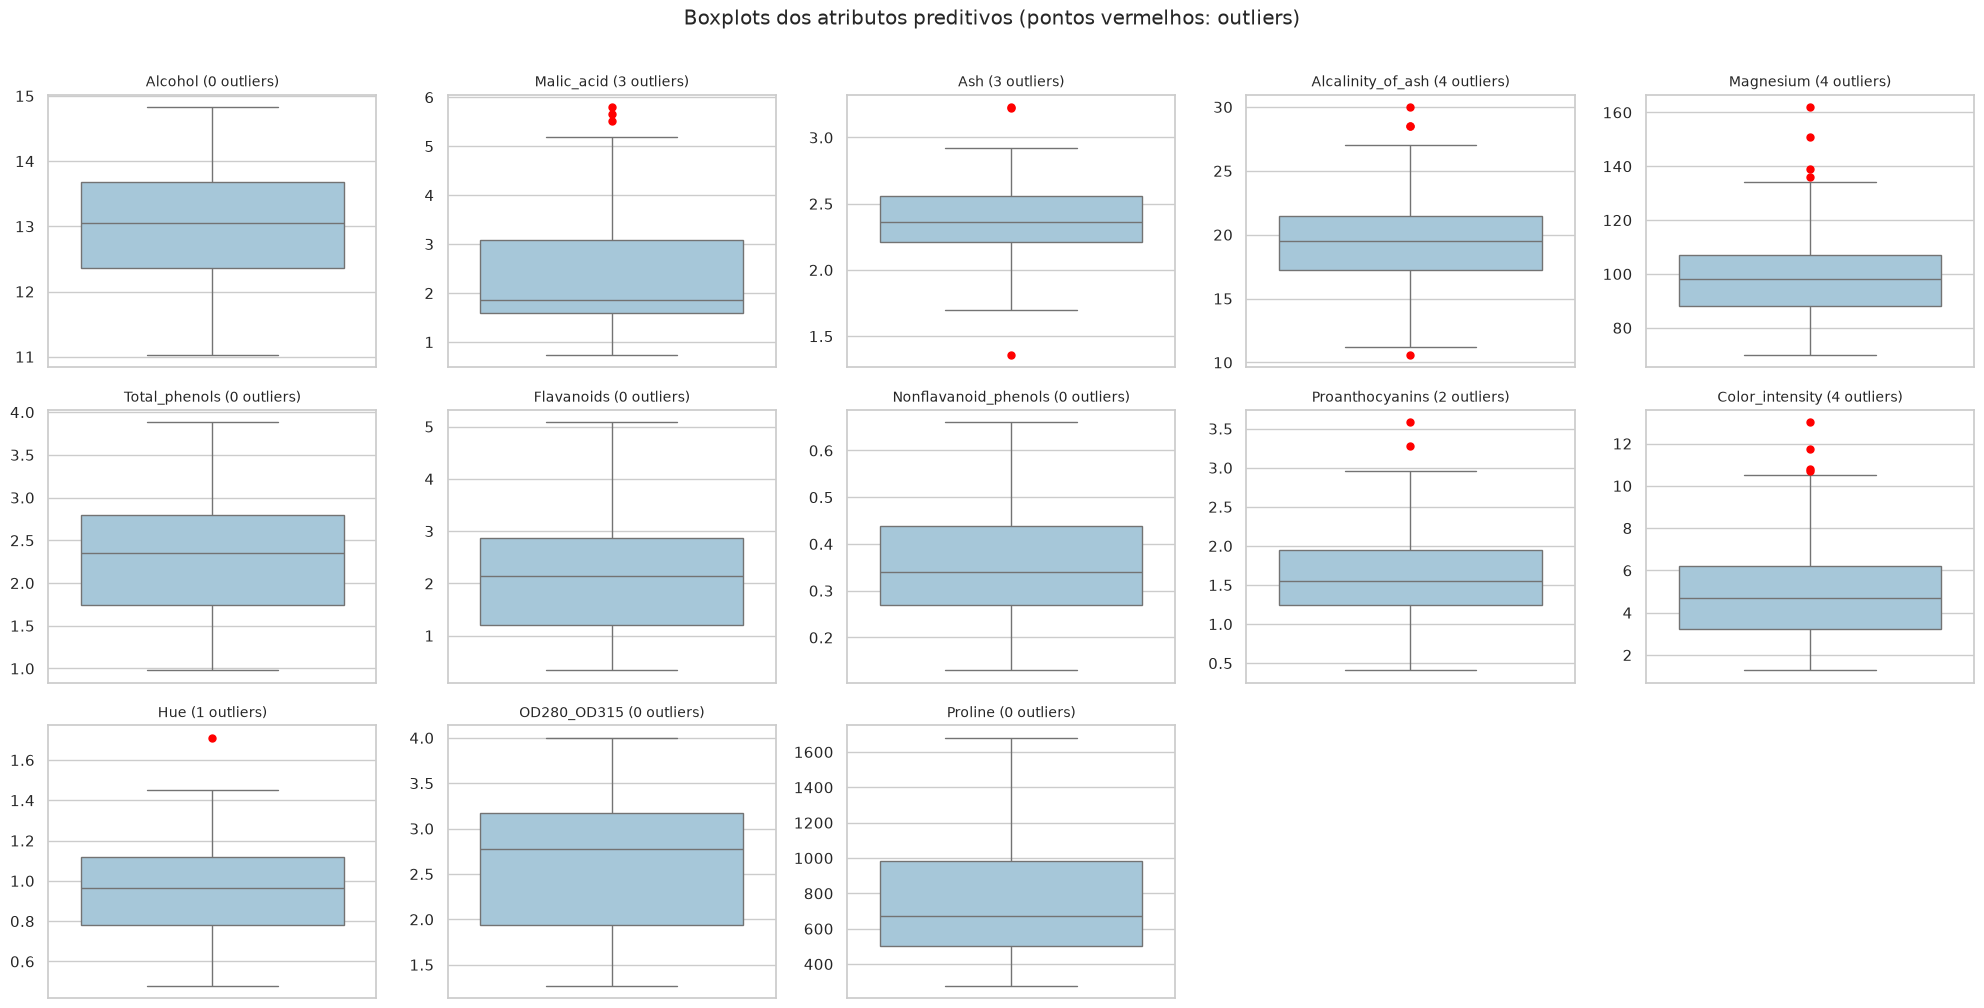

In [ ]:
fig, axs = plt.subplots(3, 5, figsize=(20, 10))
axs = axs.ravel()
for ax, c in zip(axs, COLUNAS):
    sns.boxplot(y=X[c], ax=ax, color="#9ecae1", whis=1.5,
                flierprops=dict(marker="o", markerfacecolor="red", markeredgecolor="red", markersize=5))
    ax.set_title(f"{c} ({outlier[c].sum()} outliers)", fontsize=10)
    ax.set_ylabel("")
for ax in axs[len(COLUNAS):]:
    ax.axis("off")
plt.suptitle("Boxplots dos atributos preditivos (pontos vermelhos: outliers)", y=1.01)
plt.tight_layout()
plt.show()

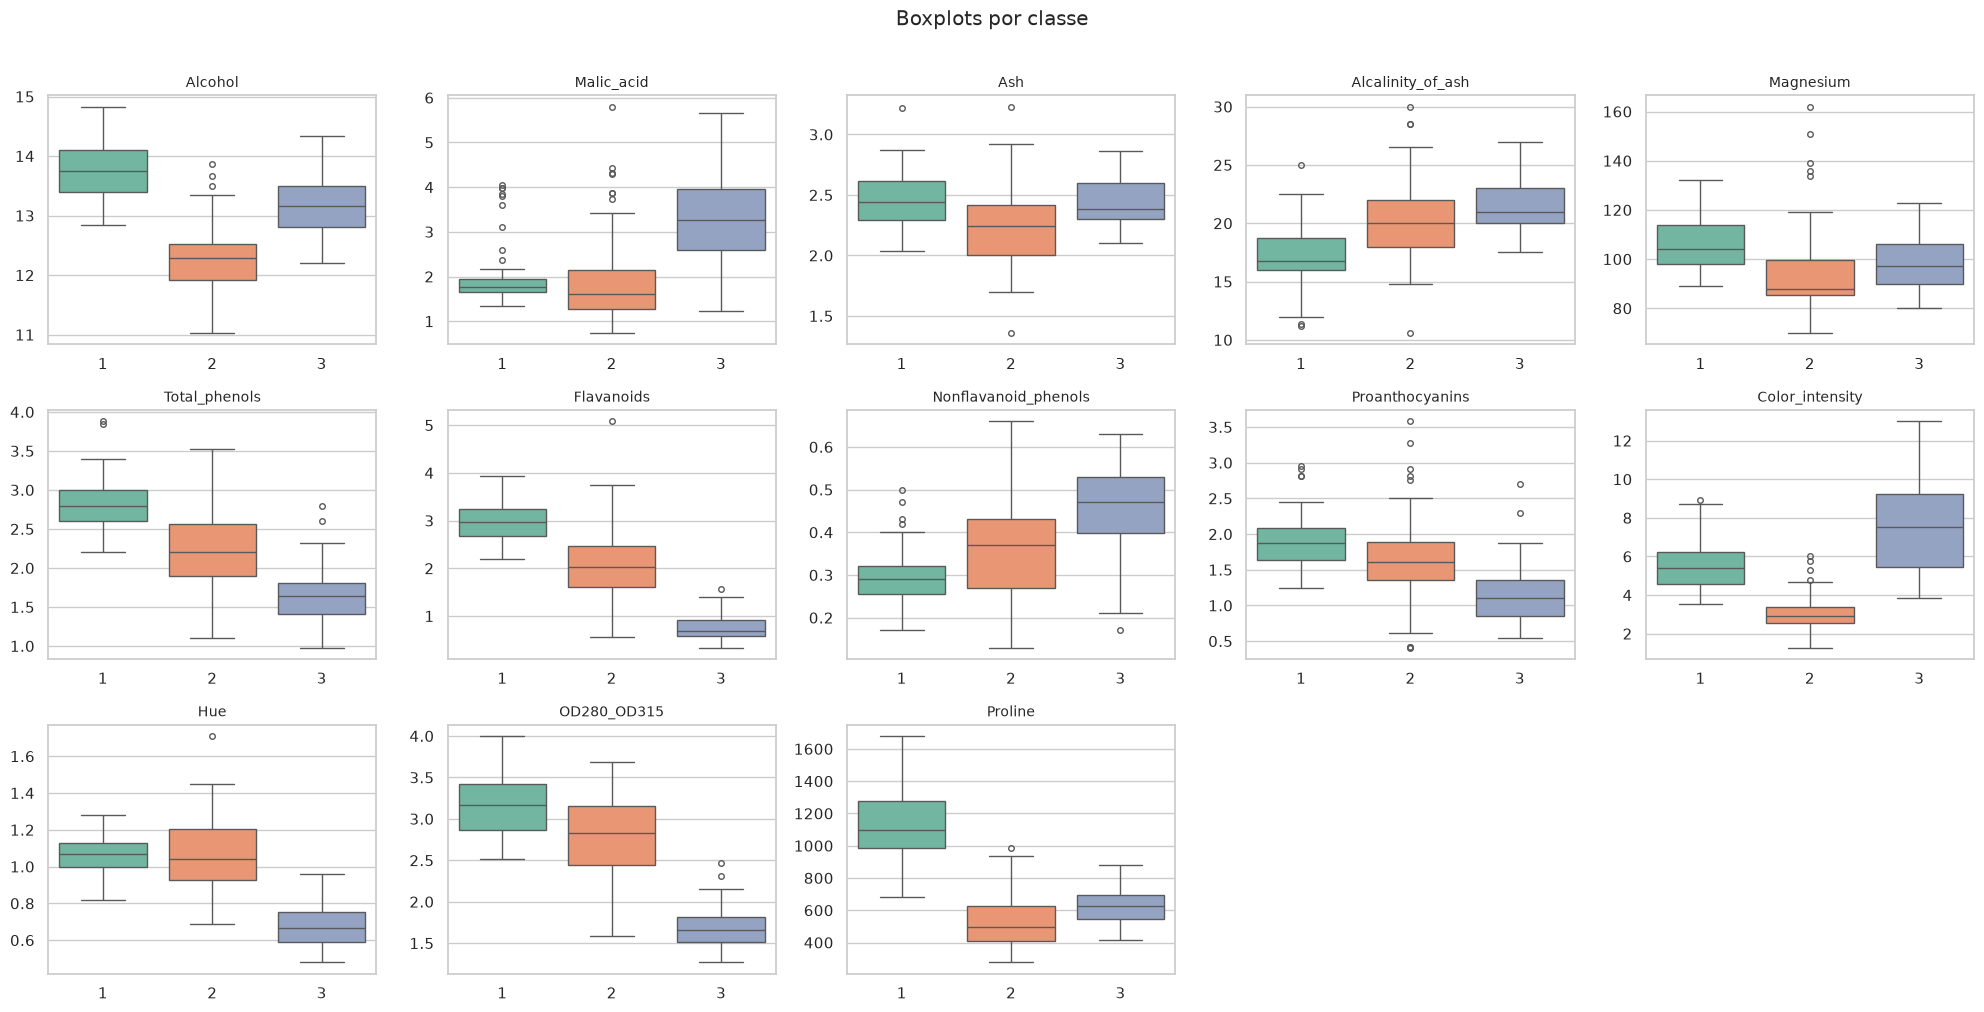

Outliers (critério do boxplot sobre o conjunto completo) por classe:


,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Proanthocyanins,Color_intensity,Hue
Class,,,,,,,
1,0,1,0,0,0,0,0
2,1,2,4,4,2,0,1
3,2,0,0,0,0,4,0


Mediana de cada atributo por classe:


Class,1,2,3
Alcohol,13.750,12.290,13.165
Malic_acid,1.770,1.610,3.265
Ash,2.440,2.240,2.380
Alcalinity_of_ash,16.800,20.000,21.000
Magnesium,104.000,88.000,97.000
Total_phenols,2.800,2.200,1.635
Flavanoids,2.980,2.030,0.685
Nonflavanoid_phenols,0.290,0.370,0.470
Proanthocyanins,1.870,1.610,1.105
Color_intensity,5.400,2.900,7.550


In [ ]:
fig, axs = plt.subplots(3, 5, figsize=(20, 10))
axs = axs.ravel()
for ax, c in zip(axs, COLUNAS):
    sns.boxplot(data=df, x="Class", y=c, hue="Class", palette="Set2", legend=False, ax=ax, fliersize=4)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axs[len(COLUNAS):]:
    ax.axis("off")
plt.suptitle("Boxplots por classe", y=1.01)
plt.tight_layout()
plt.show()

print("Outliers (critério do boxplot sobre o conjunto completo) por classe:")
display(outlier.groupby(y).sum().loc[:, outlier.any()])
print("Mediana de cada atributo por classe:")
display(X.groupby(y).median().T)

Os atributos `Alcohol`, `Total_phenols`, `Flavanoids`, `Nonflavanoid_phenols`, `OD280_OD315` e `Proline` não apresentam outliers. No caso de `Proline`, a cauda à direita permanece dentro dos limites, apesar da obliquidade positiva. Nos demais atributos há de 1 a 4 outliers, situados predominantemente acima de Q3, o que é coerente com a obliquidade positiva calculada no item c. Apenas `Ash` e `Alcalinity_of_ash` apresentam, cada um, um outlier abaixo de Q1.

Os outliers concentram-se na classe 2 (14 ocorrências), seguida das classes 3 (6) e 1 (1), com destaque para `Alcalinity_of_ash` e `Magnesium` na classe 2 e `Color_intensity` na classe 3. Os boxplots por classe mostram que parte dos valores extremos no conjunto completo decorre da diferença entre cultivares: a classe 3 tem medianas de `Color_intensity` (7,55) e de `Malic_acid` (3,265) bem acima das demais classes, e concentra os 4 outliers de `Color_intensity` e 2 dos 3 outliers de `Malic_acid`.

Os boxplots por classe também indicam os atributos que melhor diferenciam as cultivares. `Flavanoids`, `OD280_OD315`, `Total_phenols` e `Proline` apresentam caixas pouco sobrepostas entre as classes. Por exemplo, a mediana de `Proline` é 1095 na classe 1, contra 495 e 627,5 nas classes 2 e 3, e a mediana de `Flavanoids` é 0,685 na classe 3, contra 2,98 e 2,03 nas classes 1 e 2. Os outliers foram mantidos, pelos motivos apresentados no item d.

## g) Histogramas

O histograma divide os valores de um atributo em intervalos contíguos de mesmo tamanho e representa por uma barra a quantidade de valores em cada intervalo. Nos histogramas gerais, as linhas verticais indicam a média e a mediana de cada atributo, para comparação com as medidas do item c.

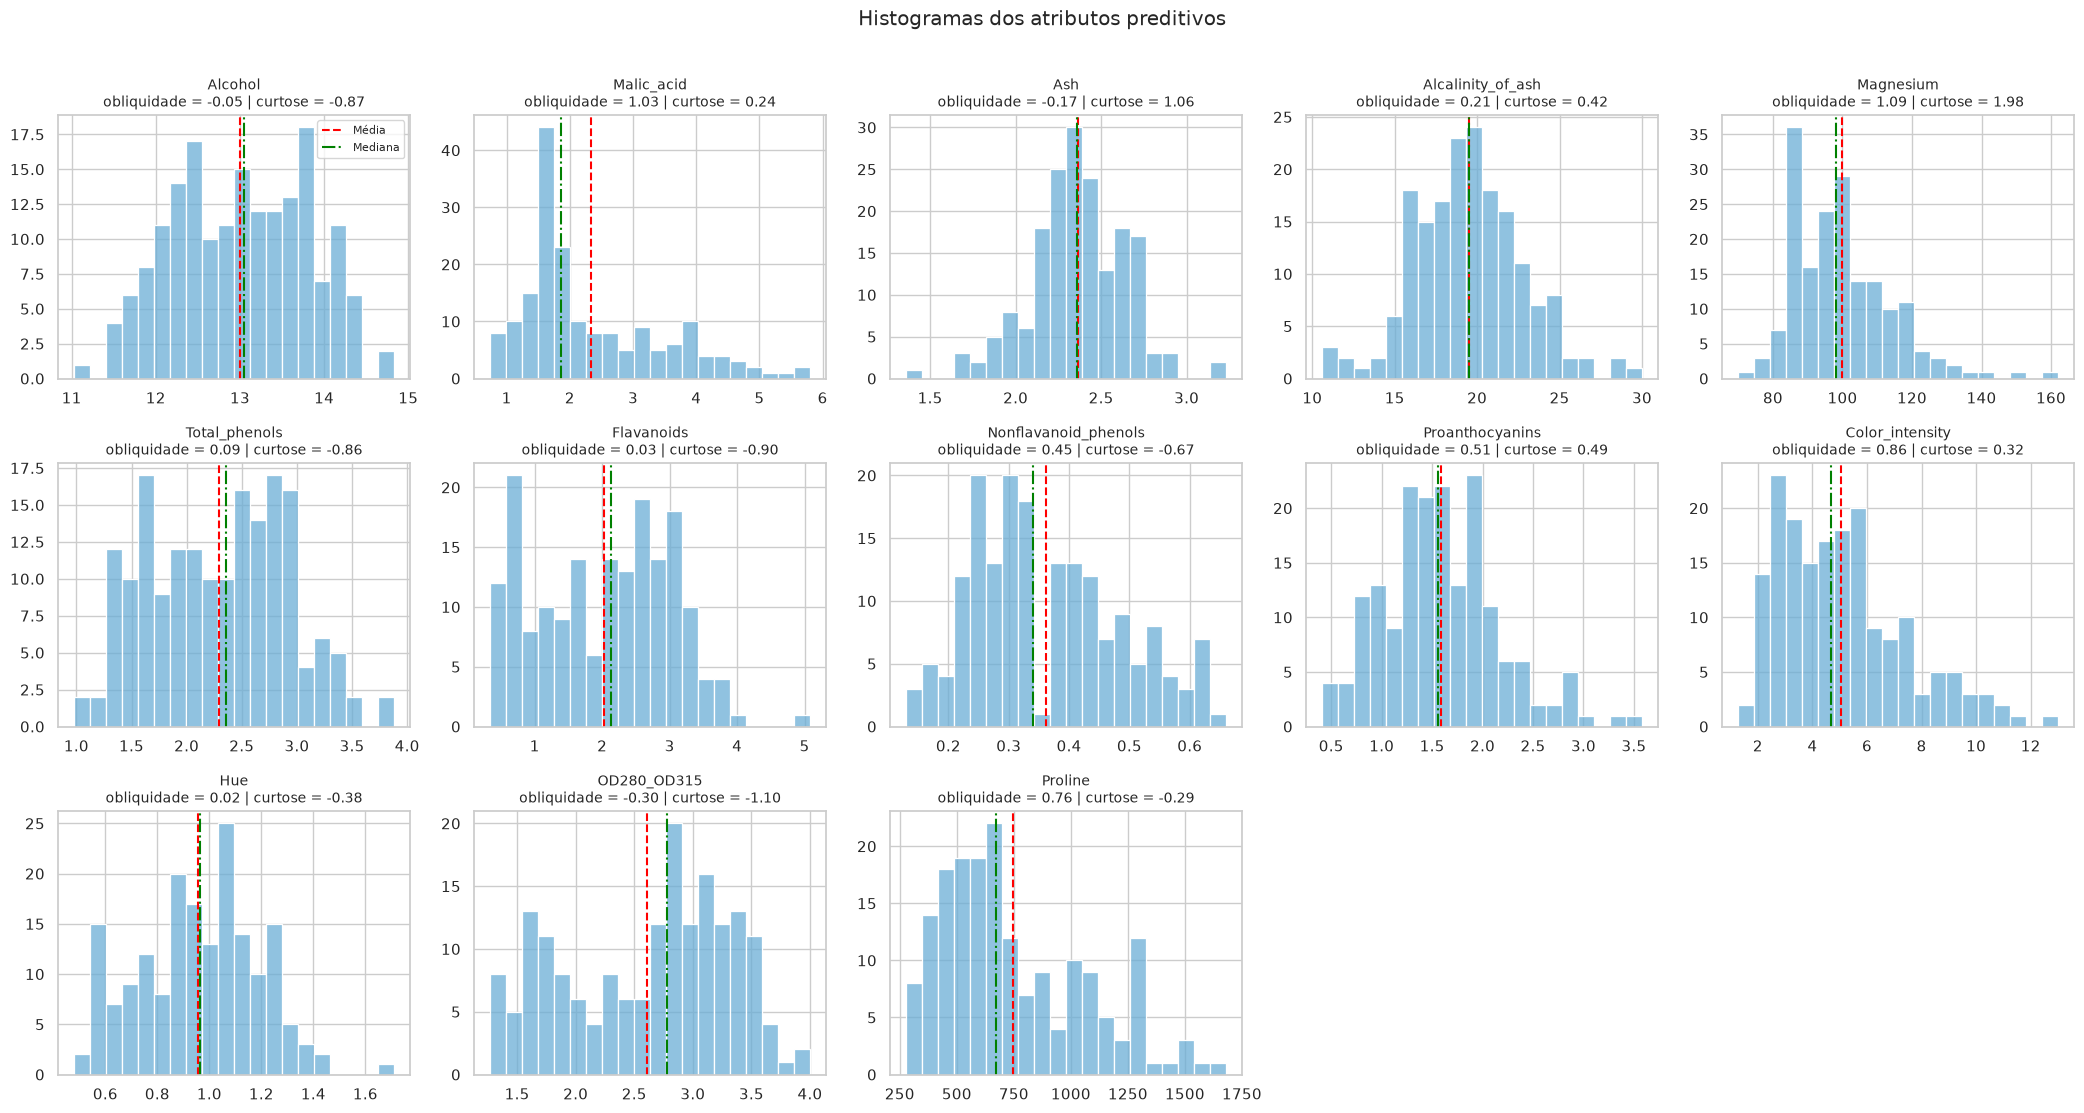

In [ ]:
fig, axs = plt.subplots(3, 5, figsize=(21, 11))
axs = axs.ravel()
for ax, c in zip(axs, COLUNAS):
    sns.histplot(X[c], bins=20, color="#6baed6", edgecolor="w", ax=ax)
    ax.axvline(X[c].mean(), color="red", ls="--", lw=1.5, label="Média")
    ax.axvline(X[c].median(), color="green", ls="-.", lw=1.5, label="Mediana")
    ax.set_title(f"{c}\nobliquidade = {obliquidade(X[c]):.2f} | curtose = {curtose(X[c]):.2f}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
axs[0].legend(fontsize=8)
for ax in axs[len(COLUNAS):]:
    ax.axis("off")
plt.suptitle("Histogramas dos atributos preditivos", y=1.01)
plt.tight_layout()
plt.show()

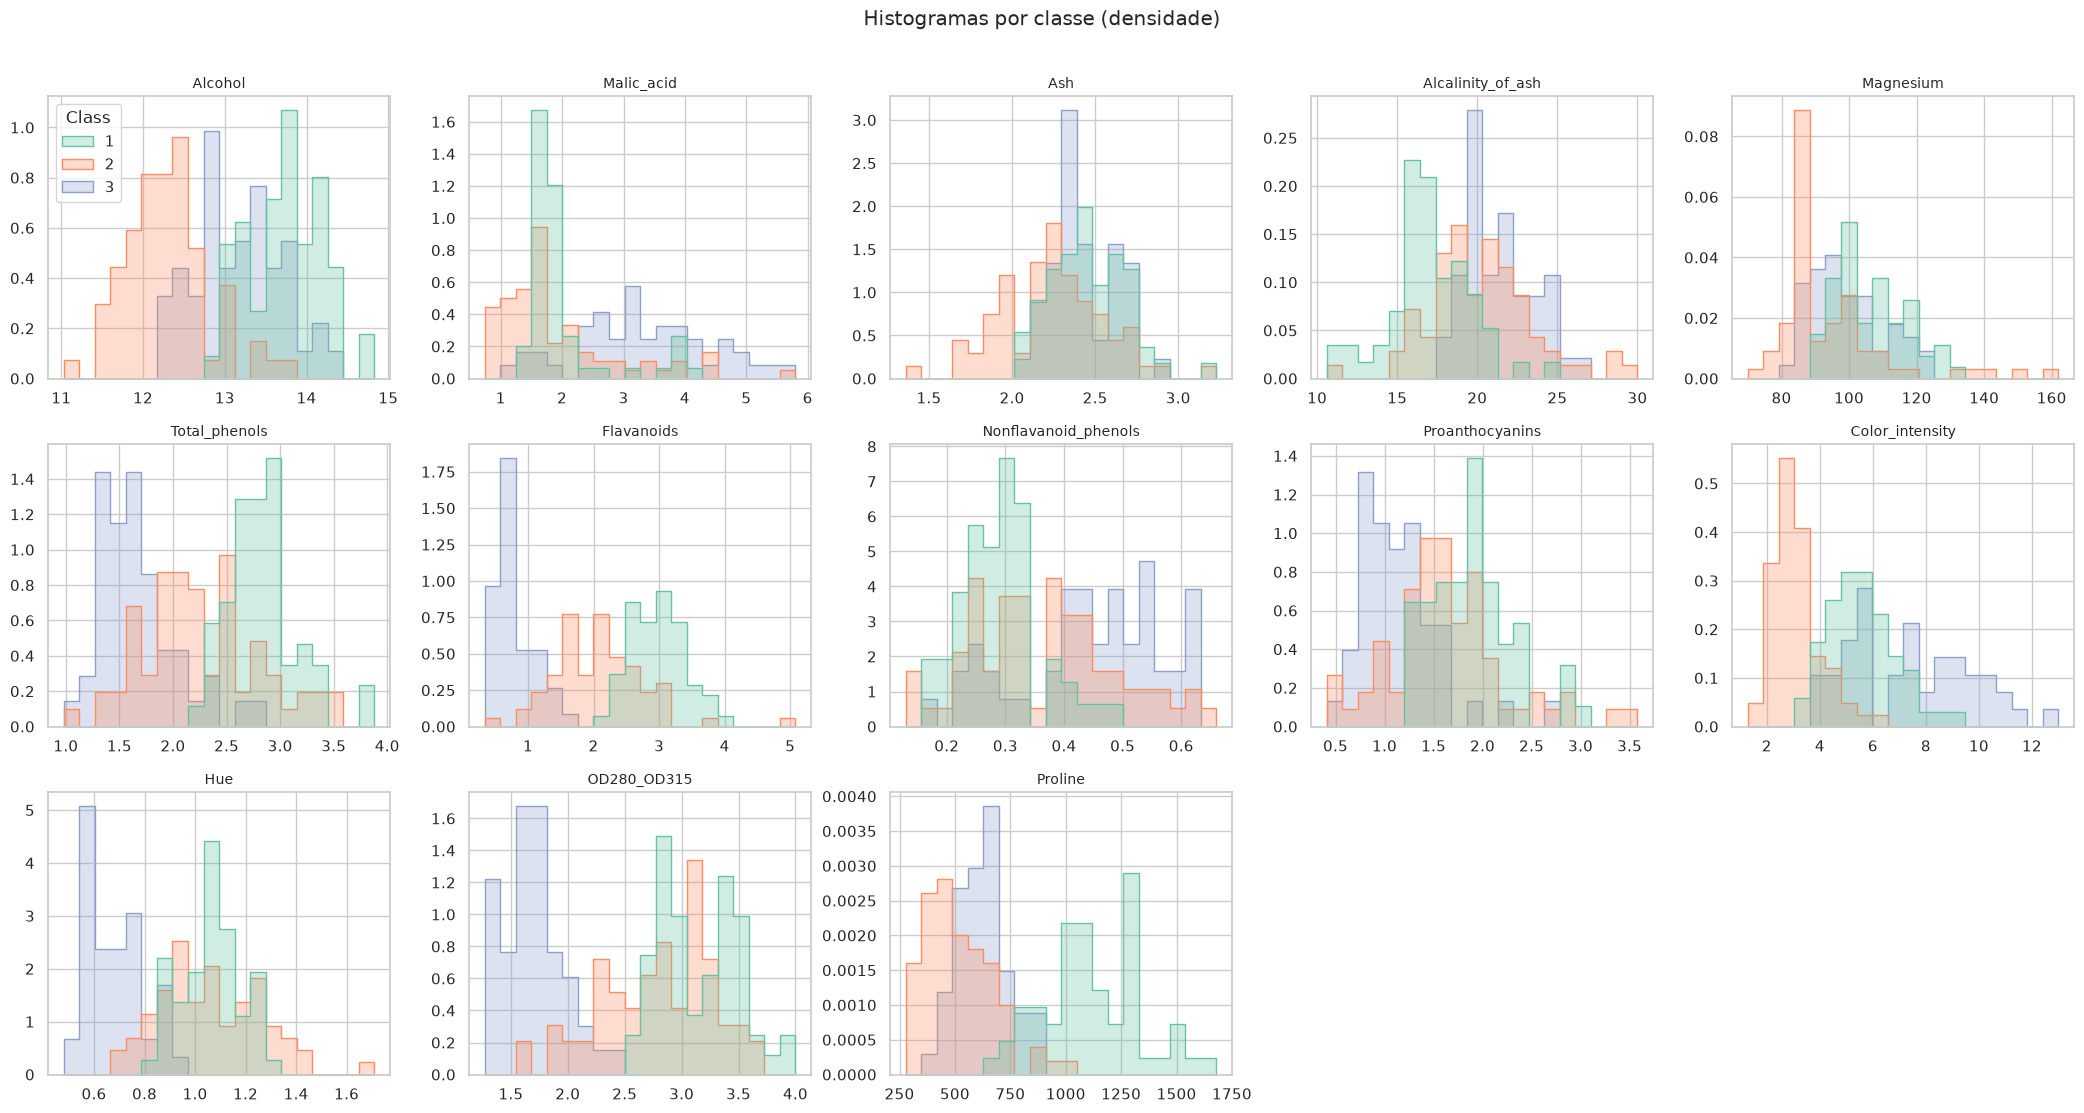

In [ ]:
fig, axs = plt.subplots(3, 5, figsize=(21, 11))
axs = axs.ravel()
for ax, c in zip(axs, COLUNAS):
    sns.histplot(data=df, x=c, hue="Class", palette="Set2", bins=20, stat="density", common_norm=False,
                 element="step", alpha=0.3, ax=ax, legend=(c == COLUNAS[0]))
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axs[len(COLUNAS):]:
    ax.axis("off")
plt.suptitle("Histogramas por classe (densidade)", y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# Obliquidade e curtose por classe, com as mesmas fórmulas do item c
por_classe = pd.DataFrame({"Obliquidade (geral)": obliquidade(X), "Curtose (geral)": curtose(X)})
for k_classe in sorted(y.unique()):
    Xk = X[y == k_classe]
    por_classe[f"Obliquidade (classe {k_classe})"] = obliquidade(Xk)
    por_classe[f"Curtose (classe {k_classe})"] = curtose(Xk)
por_classe.round(2)

,Obliquidade (geral),Curtose (geral),Obliquidade (classe 1),Curtose (classe 1),Obliquidade (classe 2),Curtose (classe 2),Obliquidade (classe 3),Curtose (classe 3)
Alcohol,-0.050,-0.870,0.070,-0.640,0.560,0.560,0.150,-0.710
Malic_acid,1.030,0.240,2.060,2.940,1.580,2.280,0.100,-0.480
Ash,-0.170,1.060,0.530,0.640,0.170,0.730,0.350,-0.880
Alcalinity_of_ash,0.210,0.420,0.200,0.930,0.420,1.000,0.450,-0.640
Magnesium,1.090,1.980,0.480,-0.580,2.050,4.560,0.520,-0.670
Total_phenols,0.090,-0.860,0.790,0.950,0.350,-0.420,0.980,1.210
Flavanoids,0.030,-0.900,0.260,-0.610,1.140,3.240,0.970,-0.070
Nonflavanoid_phenols,0.450,-0.670,0.700,0.680,0.340,-0.440,-0.510,-0.650
Proanthocyanins,0.510,0.490,0.610,0.070,0.660,1.290,1.510,3.290
Color_intensity,0.860,0.320,0.570,-0.030,1.010,1.080,0.290,-0.870


**Comparação com a estatística descritiva.** Nos atributos com obliquidade próxima de zero (`Alcohol`, `Ash`, `Alcalinity_of_ash`, `Total_phenols` e `Hue`), média e mediana praticamente coincidem e os histogramas são aproximadamente simétricos. Em `Malic_acid`, `Magnesium`, `Color_intensity` e `Proline`, a média situa-se à direita da mediana e a cauda direita é visível, como indicava a obliquidade positiva. O pico pronunciado do histograma de `Magnesium` corresponde à sua curtose positiva.

**Influência das classes.** Os histogramas por classe mostram que os atributos com curtose negativa no conjunto completo (`OD280_OD315`, `Flavanoids`, `Alcohol` e `Total_phenols`) são aqueles em que as classes se concentram em regiões diferentes. Em `Flavanoids`, por exemplo, as medianas das classes 1, 2 e 3 são 2,98, 2,03 e 0,685. A sobreposição de três grupos deslocados produz um histograma geral mais achatado que o de uma distribuição normal. A tabela por classe reforça essa interpretação: em cada um desses quatro atributos, ao menos uma das classes apresenta curtose positiva, ou seja, o achatamento observado no conjunto completo não se repete de forma sistemática dentro das classes.

Separar as classes, contudo, não torna as distribuições simétricas. Em alguns atributos a obliquidade é maior dentro de uma classe do que no conjunto completo, como `Malic_acid` nas classes 1 e 2 (2,06 e 1,58) e `Magnesium` na classe 2 (2,05). Isso indica que a cauda à direita desses atributos provém de classes específicas. Como cada classe tem entre 48 e 71 objetos, essas estimativas são menos precisas que as calculadas sobre o conjunto completo.

**Atributos discriminantes.** Os atributos cujas distribuições por classe se sobrepõem menos são `Flavanoids`, `OD280_OD315`, `Total_phenols` e `Proline`, seguidos de `Alcohol`, `Color_intensity` e `Hue`, que separam bem ao menos uma das classes. `Ash` e `Magnesium` apresentam grande sobreposição entre as classes, o que sugere menor contribuição para a discriminação das cultivares.

## h) Transformação dos dados

A transformação de atributos numéricos é recomendada quando os limites de valores dos atributos são muito diferentes, para evitar que um atributo predomine sobre os demais. É o caso do banco Wine, conforme observado nos itens b e c. Métodos baseados em distância e redes neurais artificiais são sensíveis a essa diferença de escala, assim como a análise de componentes principais, que se baseia na variância dos atributos.

Foram comparadas as formas de normalização apresentadas em aula:

- **reescala (normalização min-max)**: leva os valores ao intervalo [0, 1] a partir do mínimo e do máximo de cada atributo;
- **padronização**: subtrai a média e divide pelo desvio padrão, $z = (x - \mu)/\sigma$, resultando em média 0 e desvio padrão 1;
- **normalização por distribuição**: substitui cada valor pela sua posição no ranking dos valores do atributo.

,Média (original),Desvio padrão (original),Média (padronizado),Desvio padrão (padronizado)
Alcohol,13.001,0.812,-0.000,1.000
Malic_acid,2.336,1.117,-0.000,1.000
Ash,2.367,0.274,-0.000,1.000
Alcalinity_of_ash,19.495,3.340,-0.000,1.000
Magnesium,99.742,14.282,-0.000,1.000
Total_phenols,2.295,0.626,0.000,1.000
Flavanoids,2.029,0.999,-0.000,1.000
Nonflavanoid_phenols,0.362,0.124,0.000,1.000
Proanthocyanins,1.591,0.572,-0.000,1.000
Color_intensity,5.058,2.318,0.000,1.000


Obliquidade preservada pela padronização: True
Curtose preservada pela padronização: True
Magnesium: fração do intervalo [0, 1] ocupada pela metade central dos dados após a reescala: 0.21


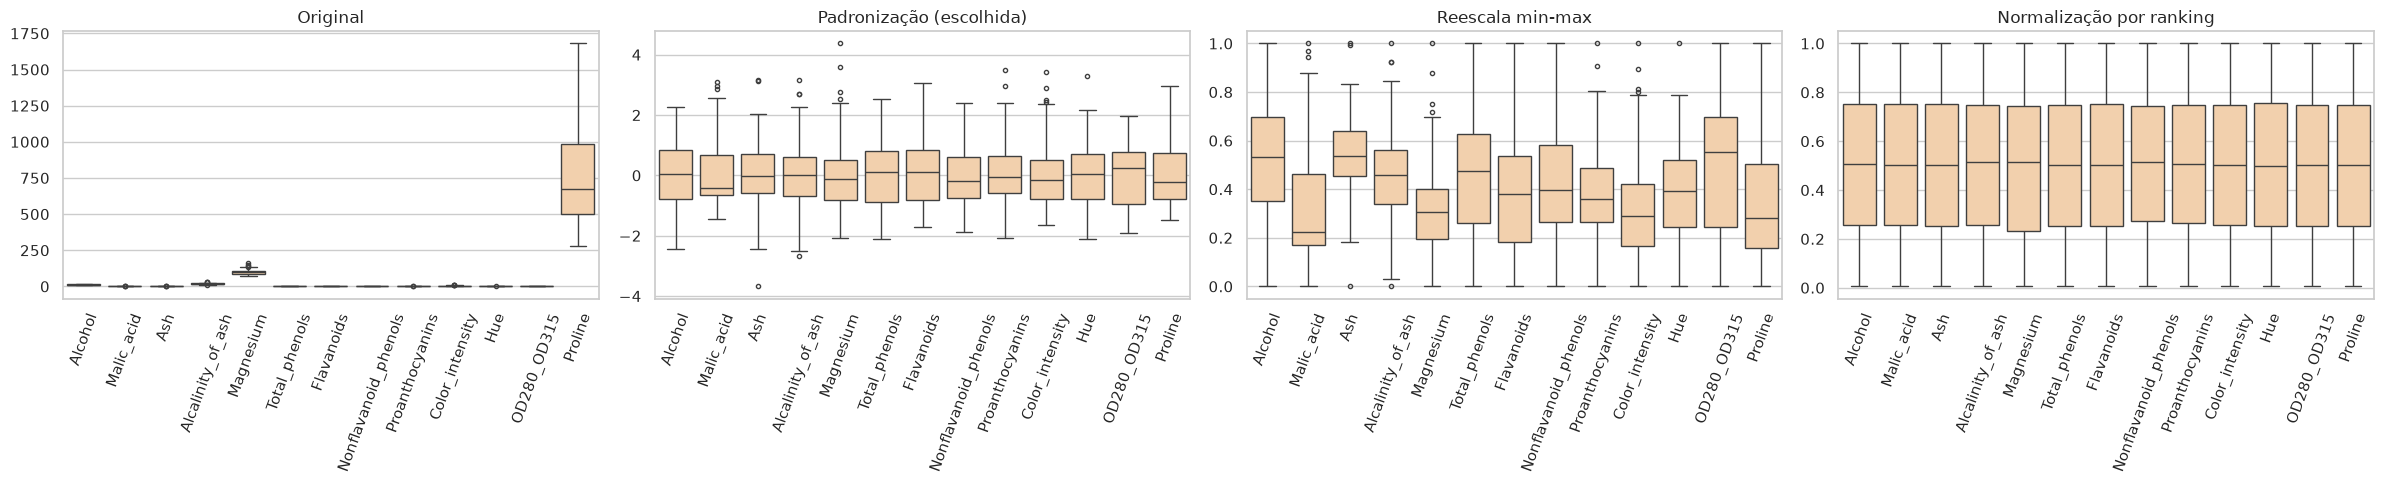

In [ ]:
scaler = StandardScaler()
X_pad = pd.DataFrame(scaler.fit_transform(X), columns=COLUNAS, index=X.index)
X_minmax = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=COLUNAS, index=X.index)
X_rank = X.rank(pct=True)

# O StandardScaler utiliza o desvio padrão populacional (denominador n); por isso, o desvio padrão
# dos atributos padronizados é calculado com ddof=0 para a verificação
verificacao = pd.DataFrame({"Média (original)": X.mean(), "Desvio padrão (original)": X.std(),
                            "Média (padronizado)": X_pad.mean(), "Desvio padrão (padronizado)": X_pad.std(ddof=0)})
display(verificacao)

print("Obliquidade preservada pela padronização:", np.allclose(obliquidade(X), obliquidade(X_pad)))
print("Curtose preservada pela padronização:", np.allclose(curtose(X), curtose(X_pad)))

m = X["Magnesium"]
print(f"Magnesium: fração do intervalo [0, 1] ocupada pela metade central dos dados após a reescala: "
      f"{(m.quantile(0.75) - m.quantile(0.25)) / (m.max() - m.min()):.2f}")

fig, axs = plt.subplots(1, 4, figsize=(24, 5))
for ax, (nome, D) in zip(axs, [("Original", X), ("Padronização (escolhida)", X_pad),
                               ("Reescala min-max", X_minmax), ("Normalização por ranking", X_rank)]):
    sns.boxplot(data=D, ax=ax, color="#fdd0a2", fliersize=3)
    ax.set_title(nome)
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

Optou-se pela **padronização**. Após a transformação, todos os atributos têm média 0 e desvio padrão 1, e os boxplots passam a ocupar faixas comparáveis. Por ser uma transformação linear, a padronização altera apenas a escala dos atributos e preserva a forma das distribuições: a obliquidade e a curtose permanecem as mesmas, como confirma o código, assim como a posição relativa dos outliers.

A reescala min-max também equaliza as faixas, mas depende exclusivamente dos valores mínimo e máximo. Em atributos com outliers, um único valor extremo comprime os demais em uma parte estreita do intervalo [0, 1]: em `Magnesium`, a metade central dos dados (entre Q1 e Q3) ocupa apenas 21% do intervalo após a reescala. Por isso, a padronização lida melhor com outliers. A normalização por ranking produz distribuições aproximadamente uniformes e, portanto, descarta a forma original dos dados, analisada nos itens c e g. Por fim, a padronização é a preparação usual para a análise de componentes principais, pois iguala a variância de todos os atributos e faz com que cada um contribua de forma equivalente.

Em uma etapa de modelagem, os parâmetros da padronização (média e desvio padrão) devem ser estimados apenas com o conjunto de treinamento e então aplicados ao conjunto de teste, para que este não influencie a construção do modelo. Neste trabalho, de caráter exploratório, a padronização foi ajustada sobre o conjunto completo.

## i) Análise de componentes principais (PCA)

A análise de componentes principais (PCA, do inglês *Principal Component Analysis*) é uma técnica de redução de dimensionalidade por **agregação**: os atributos originais são substituídos por novos atributos, os componentes principais, obtidos como combinações lineares dos originais. Os componentes são ortogonais entre si e ordenados pela variância que explicam, de modo que os primeiros concentram a maior parte da variabilidade dos dados. Ao combinar atributos correlacionados, a PCA descorrelaciona os dados e elimina redundâncias, ao custo de perder os valores originais dos atributos.

A PCA é uma técnica não supervisionada: os componentes são calculados sem utilizar o atributo alvo. As classes são usadas apenas para colorir os gráficos e verificar se a estrutura encontrada reflete as cultivares. A técnica foi aplicada aos atributos padronizados no item h.

,Variância explicada (%),Variância acumulada (%)
PC1,36.200,36.200
PC2,19.200,55.400
PC3,11.100,66.500
PC4,7.100,73.600
PC5,6.600,80.200
PC6,4.900,85.100
PC7,4.200,89.300
PC8,2.700,92.000
PC9,2.200,94.200
PC10,1.900,96.200


Componentes necessários para explicar ao menos 80% da variância: 5


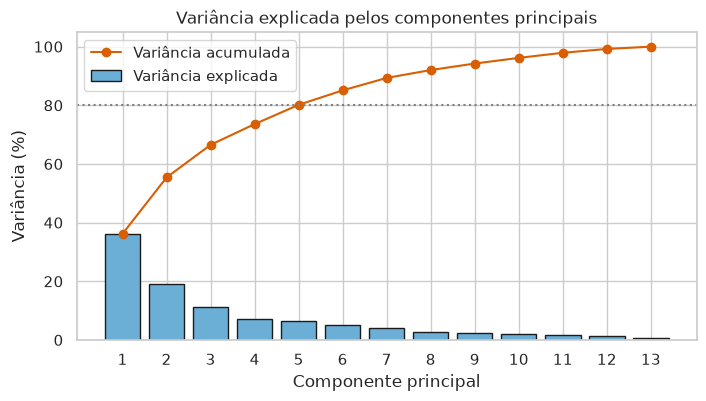

In [ ]:
pca = PCA().fit(X_pad)
var = pca.explained_variance_ratio_
variancia = pd.DataFrame({"Variância explicada (%)": 100 * var, "Variância acumulada (%)": 100 * var.cumsum()},
                         index=[f"PC{i + 1}" for i in range(len(var))])
display(variancia.round(1))
print("Componentes necessários para explicar ao menos 80% da variância:", int(np.argmax(var.cumsum() >= 0.80) + 1))

plt.figure(figsize=(8, 4))
plt.bar(range(1, 14), 100 * var, color="#6baed6", edgecolor="k", label="Variância explicada")
plt.plot(range(1, 14), 100 * var.cumsum(), "o-", color="#d95f02", label="Variância acumulada")
plt.axhline(80, ls=":", c="gray")
plt.xticks(range(1, 14))
plt.xlabel("Componente principal")
plt.ylabel("Variância (%)")
plt.title("Variância explicada pelos componentes principais")
plt.legend()
plt.show()

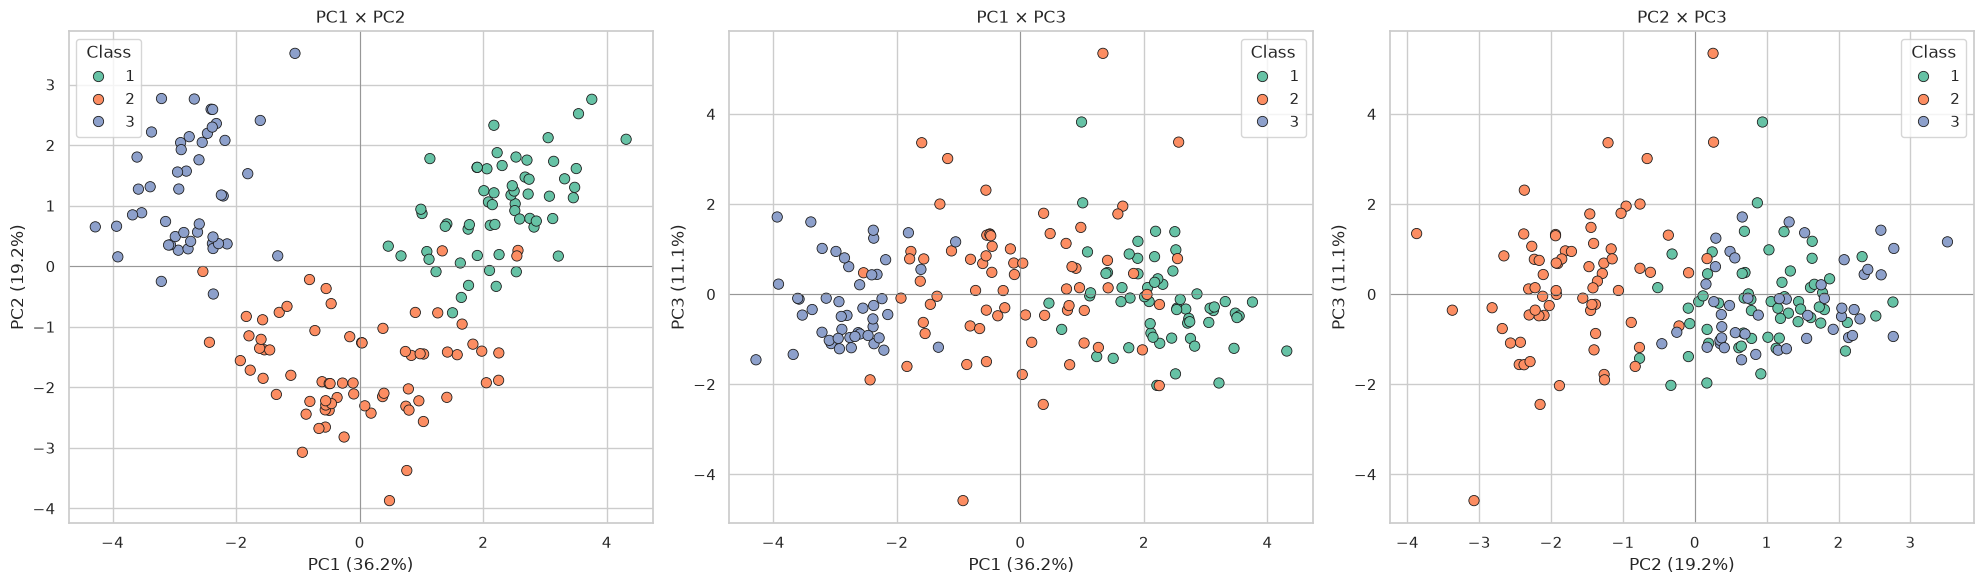

In [ ]:
componentes = pd.DataFrame(pca.transform(X_pad), columns=[f"PC{i + 1}" for i in range(13)], index=X.index)
componentes["Class"] = y.values

fig, axs = plt.subplots(1, 3, figsize=(20, 6))
for ax, (a, b) in zip(axs, [("PC1", "PC2"), ("PC1", "PC3"), ("PC2", "PC3")]):
    sns.scatterplot(data=componentes, x=a, y=b, hue="Class", palette="Set2", s=55, edgecolor="k", ax=ax)
    i, j = int(a[2:]) - 1, int(b[2:]) - 1
    ax.set(xlabel=f"{a} ({100 * var[i]:.1f}%)", ylabel=f"{b} ({100 * var[j]:.1f}%)", title=f"{a} × {b}")
    ax.axhline(0, c="gray", lw=0.5)
    ax.axvline(0, c="gray", lw=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Cargas: peso de cada atributo nos dois primeiros componentes
cargas = pd.DataFrame(pca.components_[:2].T, index=COLUNAS, columns=["PC1", "PC2"])
cargas.round(2).sort_values("PC1", ascending=False)

,PC1,PC2
Flavanoids,0.420,-0.000
Total_phenols,0.390,0.070
OD280_OD315,0.380,-0.160
Proanthocyanins,0.310,0.040
Hue,0.300,-0.280
Proline,0.290,0.360
Alcohol,0.140,0.480
Magnesium,0.140,0.300
Ash,-0.000,0.320
Color_intensity,-0.090,0.530


,Sem normalização,Reescala min-max,Padronização
PC1 (%),99.800,40.700,36.200
PC2 (%),0.200,19.000,19.200
PC3 (%),0.000,8.600,11.100


Sem normalização, o atributo de maior carga no PC1 é Proline (módulo da carga = 0.9998)


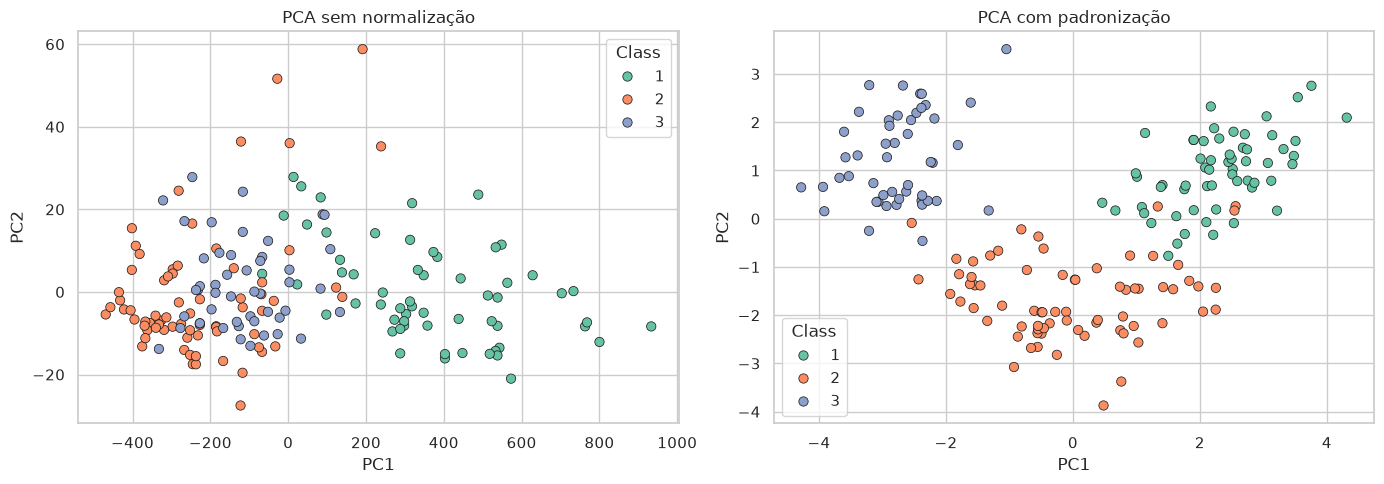

In [ ]:
# Efeito da transformação: PCA sem normalização, com reescala min-max e com padronização
pca_original = PCA().fit(X)
pca_minmax = PCA().fit(X_minmax)
comparacao = pd.DataFrame({
    "Sem normalização": 100 * pca_original.explained_variance_ratio_[:3],
    "Reescala min-max": 100 * pca_minmax.explained_variance_ratio_[:3],
    "Padronização": 100 * var[:3],
}, index=["PC1 (%)", "PC2 (%)", "PC3 (%)"])
display(comparacao.round(1))

carga_pc1_original = pd.Series(pca_original.components_[0], index=COLUNAS).abs()
print(f"Sem normalização, o atributo de maior carga no PC1 é {carga_pc1_original.idxmax()} "
      f"(módulo da carga = {carga_pc1_original.max():.4f})")

originais = pd.DataFrame(pca_original.transform(X)[:, :2], columns=["PC1", "PC2"])
originais["Class"] = y.values
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=originais, x="PC1", y="PC2", hue="Class", palette="Set2", s=45, edgecolor="k", ax=axs[0])
axs[0].set_title("PCA sem normalização")
sns.scatterplot(data=componentes, x="PC1", y="PC2", hue="Class", palette="Set2", s=45, edgecolor="k", ax=axs[1])
axs[1].set_title("PCA com padronização")
plt.tight_layout()
plt.show()

**Variância explicada.** O primeiro componente (PC1) explica 36,2% da variância total e o segundo (PC2), 19,2%, totalizando 55,4%. Com três componentes atinge-se 66,5%, e são necessários cinco componentes para superar 80%. A ausência de um componente dominante é coerente com as correlações moderadas observadas no item e: a redundância concentra-se no grupo dos compostos fenólicos, e os demais atributos contribuem com informação própria.

**Interpretação dos componentes.** As cargas indicam o peso de cada atributo em cada componente. O PC1 tem as maiores cargas positivas em `Flavanoids`, `Total_phenols` e `OD280_OD315` e as maiores cargas negativas em `Nonflavanoid_phenols`, `Malic_acid` e `Alcalinity_of_ash`, de modo que representa principalmente o conteúdo fenólico. O PC2 tem as maiores cargas em `Color_intensity`, `Alcohol`, `Proline` e `Ash`.

**Espaço dos componentes.** No plano PC1 × PC2, as três cultivares formam grupos bem definidos, com sobreposição apenas nas regiões de fronteira entre as classes 1 e 2 e entre as classes 2 e 3. Como a PCA não utilizou o atributo alvo, essa separação indica que as cultivares diferem de forma consistente em sua composição química, o que favorece a tarefa de classificação. A documentação do banco também descreve as classes como separáveis. Nos planos que envolvem o PC3, a sobreposição entre classes é maior, o que torna o plano PC1 × PC2 o mais informativo para visualização.

**Efeito da transformação.** Sem normalização, o PC1 explica 99,8% da variância e é praticamente idêntico ao atributo `Proline` (carga de módulo próximo de 1), pois esse atributo tem a maior variância em valores absolutos. Nesse caso, a PCA ignora os demais atributos e as classes 2 e 3 permanecem sobrepostas. Com a reescala min-max, os dois primeiros componentes explicam 40,7% e 19,0% da variância, resultado próximo ao da padronização. No banco Wine, em que os outliers são poucos, as duas normalizações produzem estruturas semelhantes, e a diferença decisiva está entre normalizar ou não os dados.

**Limitações.** A PCA captura apenas relações lineares e maximiza a variância, e não a separação entre classes. Além disso, cada componente combina todos os atributos, o que dificulta a interpretação dos resultados em termos das grandezas originais.

## Conclusão

O banco Wine é um conjunto multivariado com 178 objetos, 13 atributos preditivos quantitativos de escala racional e um atributo alvo nominal com três classes. As classes apresentam desbalanceamento leve, que não justifica a aplicação de técnicas de balanceamento. O conjunto não possui valores ausentes, objetos duplicados nem inconsistências verificáveis, e os poucos outliers são plausíveis e foram mantidos. Há redundância parcial entre os atributos associados aos compostos fenólicos, tratada por agregação na análise de componentes principais.

A principal característica a ser tratada é a diferença de escala entre os atributos, resolvida pela padronização. Com os dados padronizados, os dois primeiros componentes principais explicam 55,4% da variância e já evidenciam a separação entre as três cultivares, enquanto, sem normalização, a PCA é dominada por `Proline`. Em uma etapa de modelagem, recomenda-se normalizar os atributos e avaliar o desempenho por validação cruzada estratificada, tomando como referência mínima a acurácia de 39,9% obtida ao atribuir todos os objetos à classe majoritária.

## Referências

- FERNANDES JR., A. C. L. Notas de aula da disciplina ENGG67 (Introdução ao Aprendizado de Máquina): Introdução; Análise de Dados; Pré-Processamento de Dados; Modelos Probabilísticos; Métodos Baseados em Distância; Métodos Conexionistas; Avaliação de Modelos Preditivos. Salvador: UFBA, 2026.
- FACELI, K. et al. *Inteligência Artificial: uma abordagem de aprendizado de máquina*. 2. ed. Rio de Janeiro: LTC, 2022.
- FORINA, M. et al. *Wine Recognition Data*. UCI Machine Learning Repository. Disponível em: https://archive.ics.uci.edu/dataset/109/wine.